# 04 · Profiling Cluster, Analisis Paradoks & Rekomendasi Kebijakan

Di notebook terakhir ini kita menerjemahkan angka hasil clustering dari Notebook 03 (`data/processed/provinsi_cluster.csv`) menjadi **cerita, diagnosis hambatan, dan rekomendasi kebijakan** yang bisa langsung dipakai di dashboard Streamlit.

Alur analisis:
1. **Profil angka asli & z-score per cluster** dibandingkan rata-rata nasional.
2. **Heatmap z-score & Radar chart** untuk melihat kekuatan dan kelemahan tiap cluster.
3. **Diagnosis 3 Lapis (*Akses → Pemanfaatan → Keterampilan*)** untuk mengetahui setiap cluster tertahan di lapis mana.
4. **Penamaan cluster & matriks rekomendasi kebijakan** (ditentukan dari data aktual, bukan hipotesis awal).
5. **Bedah Anomali / Paradoks Digital** (provinsi dengan akses bagus tapi adopsi/skill rendah, dan sebaliknya).
6. **Validasi eksternal & pemeriksaan provinsi perbatasan (K-Means vs Ward)**.
7. **Simpan hasil final** untuk dipakai langsung oleh `app/streamlit_app.py`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.clustering import cluster_profile
from src.config import CLUSTER_FILE, DATA_PROCESSED, FEATURES, INDICATORS, VALIDATION_VARS
from src.preprocessing import scale_features
from src.visualization import radar_chart, save_matplotlib

sns.set_theme(style="whitegrid")

df = pd.read_csv(CLUSTER_FILE)
print(f"Data dimuat: {df.shape[0]} provinsi, {df['cluster'].nunique()} cluster")

# Profil nilai asli per cluster + baris pembanding rata-rata nasional
prof_raw = cluster_profile(df, FEATURES, label_col="cluster")
nasional = df[FEATURES].mean().to_dict()
nasional["n_provinsi"] = len(df)
prof_compare = pd.concat([prof_raw, pd.DataFrame([nasional], index=["Nasional"])])

print("\n=== Rata-rata Indikator Asli per Cluster vs Nasional ===")
display(prof_compare.round(2))

# Rata-rata z-score per cluster (0 = rata-rata nasional)
X_scaled, _ = scale_features(df, FEATURES)
prof_z = X_scaled.assign(cluster=df["cluster"]).groupby("cluster")[FEATURES].mean()
print("\n=== Rata-rata Z-Score per Cluster (>0 di atas nasional, <0 di bawah nasional) ===")
display(prof_z.round(2))

Data dimuat: 38 provinsi, 4 cluster

=== Rata-rata Indikator Asli per Cluster vs Nasional ===


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls,n_provinsi
0,85.30,80.08,31.36,89.39,98.46,10.48,6
1,75.33,70.52,18.84,89.33,94.95,9.24,28
2,56.46,53.32,16.44,84.60,71.95,8.50,2
3,24.02,29.92,4.49,20.24,26.42,5.22,2
Nasional,73.21,68.99,19.93,85.45,90.68,9.19,38



=== Rata-rata Z-Score per Cluster (>0 di atas nasional, <0 di bawah nasional) ===


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls
cluster,,,,,,
0,0.87,0.99,1.72,0.23,0.45,1.03
1,0.15,0.14,-0.17,0.23,0.25,0.04
2,-1.20,-1.39,-0.53,-0.05,-1.09,-0.55
3,-3.53,-3.47,-2.33,-3.79,-3.74,-3.15


**Cara membaca tabel z-score:**
- Nilai **`> 0`** berarti rata-rata cluster berada **di atas** rata-rata nasional; nilai **`< 0`** berarti **di bawah** rata-rata nasional.
- Semakin jauh dari nol (misalnya `-3,5`), semakin ekstrem ketertinggalannya dibanding daerah lain.

## 1. Visualisasi Profil Cluster: Heatmap Z-Score & Radar Chart
Heatmap memudahkan kita membaca seluruh sel warna sekaligus (hijau = unggul, merah = tertinggal), sementara **Radar Chart** (Plotly interaktif) memperlihatkan bentuk "profil kesiapan" tiap cluster.

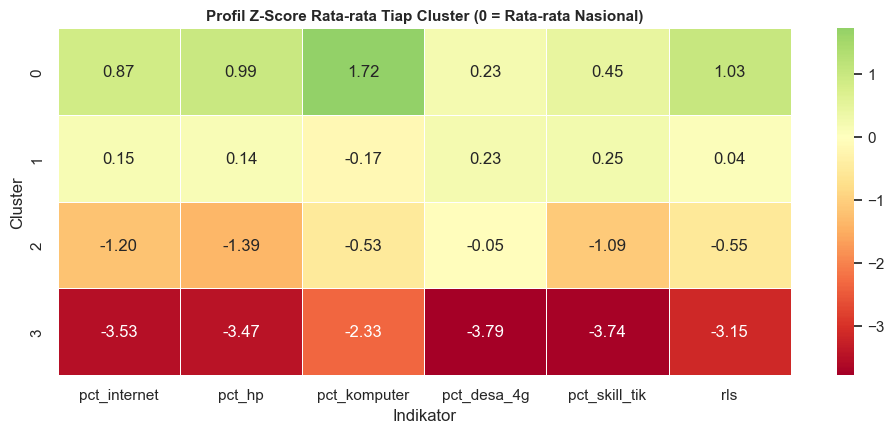

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(
    prof_z,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.6,
    ax=ax,
)
ax.set_title("Profil Z-Score Rata-rata Tiap Cluster (0 = Rata-rata Nasional)", fontsize=11, fontweight="bold")
ax.set_ylabel("Cluster")
ax.set_xlabel("Indikator")
plt.tight_layout()
save_matplotlib(fig, "04_heatmap_profil")
plt.show()

# Radar chart interaktif menggunakan fungsi di src/visualization.py
fig_radar = radar_chart(prof_z, FEATURES, title="Radar Chart Profil Cluster (Z-Score)")
fig_radar

## 2. Diagnosis 3 Lapis Kesiapan Digital (*Akses → Pemanfaatan → Keterampilan*)
Kita kelompokkan ke-6 indikator ke dalam 3 lapis kerangka berpikir:
- **Akses:** `pct_hp`, `pct_komputer`, `pct_desa_4g`
- **Pemanfaatan:** `pct_internet`
- **Keterampilan:** `pct_skill_tik`, `rls`

Dengan begitu kita bisa langsung menjawab: *setiap cluster tertahan di lapis mana?*

,Akses,Pemanfaatan,Keterampilan,lapis_terlemah
cluster,,,,
0,0.98,0.87,0.74,Keterampilan
1,0.07,0.15,0.15,Akses
2,-0.66,-1.20,-0.82,Pemanfaatan
3,-3.20,-3.53,-3.45,Pemanfaatan


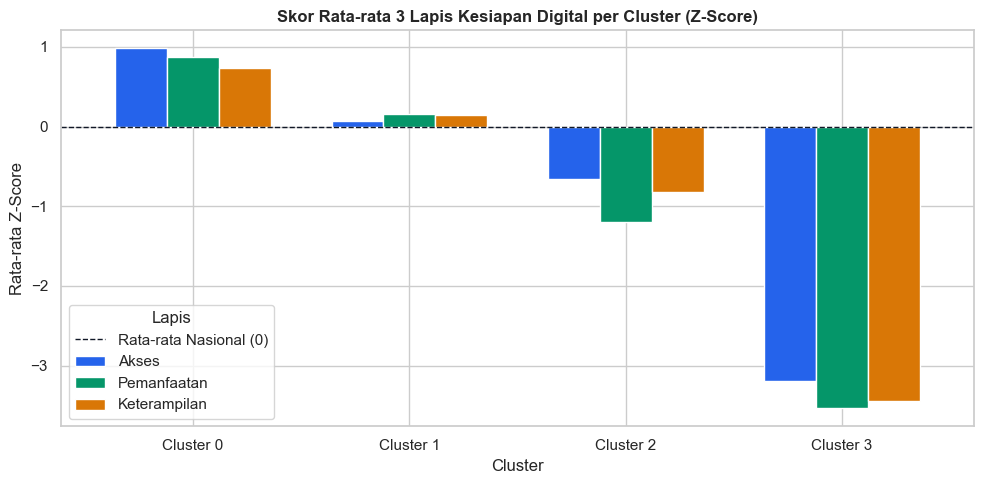

In [3]:
lapis_map = {}
for col, (_, lapis) in INDICATORS.items():
    lapis_map.setdefault(lapis, []).append(col)

lapis_order = ["Akses", "Pemanfaatan", "Keterampilan"]
lapis_scores = pd.DataFrame({
    lapis: prof_z[lapis_map[lapis]].mean(axis=1) for lapis in lapis_order
})
lapis_scores["lapis_terlemah"] = lapis_scores[lapis_order].idxmin(axis=1)
display(lapis_scores.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
lapis_scores[lapis_order].plot(
    kind="bar",
    color=["#2563eb", "#059669", "#d97706"],
    width=0.72,
    edgecolor="white",
    ax=ax,
)
ax.axhline(0, color="#111827", linewidth=1.0, linestyle="--", label="Rata-rata Nasional (0)")
ax.set_title("Skor Rata-rata 3 Lapis Kesiapan Digital per Cluster (Z-Score)", fontsize=12, fontweight="bold")
ax.set_xlabel("Cluster")
ax.set_ylabel("Rata-rata Z-Score")
ax.set_xticklabels([f"Cluster {c}" for c in lapis_scores.index], rotation=0)
ax.legend(title="Lapis")
plt.tight_layout()
save_matplotlib(fig, "04_profil_3_lapis")
plt.show()

## 3. Penamaan Cluster & Matriks Rekomendasi Kebijakan
Berdasarkan profil data aktual 38 provinsi di atas (bukan sekadar hipotesis awal), keempat cluster memiliki karakter yang sangat tegas:
- **Cluster 0 (6 provinsi):** Unggul di seluruh lapis, terutama kepemilikan komputer (~31%) dan pendidikan (RLS ~10,5 tahun).
- **Cluster 1 (28 provinsi):** Sinyal 4G (~89%) dan skill TIK (~94%) sudah tinggi, tetapi kepemilikan komputer rendah (~18,5%) — pemanfaatan masih didominasi ponsel.
- **Cluster 2 (2 provinsi — NTT & Papua Selatan):** Sinyal 4G desa sudah >82%, tetapi adopsi HP, internet, dan keterampilan TIK tertinggal tajam.
- **Cluster 3 (2 provinsi — Papua Tengah & Papua Pegunungan):** Tertinggal ekstrem di seluruh lapis sejak infrastruktur dasar (sinyal 4G hanya ~20%).

In [4]:
NAMA = {
    0: "Pusat & Motor Digital",
    1: "Terhubung Seluler, Produktivitas Belum Optimal",
    2: "Sinyal Tersedia, Adopsi & Skill Tertinggal",
    3: "Belum Terjangkau (Prioritas Infrastruktur)",
}

HAMBATAN = {
    0: "Pemerataan sinyal pedalaman/pulau (Kaltara, Kaltim, Kepri), keamanan siber & talenta digital lanjut",
    1: "Akses perangkat produktif (komputer rumah tangga rendah) & pemanfaatan produktif UMKM/pendidikan",
    2: "Adopsi internet, keterjangkauan perangkat, dan keterampilan TIK meski sinyal 4G desa >82%",
    3: "Infrastruktur dasar (sinyal 4G ~20%, listrik/akses fisik) dan pendidikan dasar (RLS rendah)",
}

REKOMENDASI = {
    0: "Dorong ekonomi digital bernilai tambah, startup hub, keamanan siber, serta tuntaskan blankspot desa terpencil.",
    1: "Perluas akses perangkat produktif (lab komputer sekolah/balai desa), pelatihan UMKM go-digital, dan literasi produktif.",
    2: "Fokus literasi digital intensif, program subsidi/akses perangkat belajar bersama, dan pendampingan komunitas lokal.",
    3: "Prioritas darurat pembangunan BTS/BAKTI & satelit (SATRIA), internet publik gratis di sekolah/puskesmas, dan percepatan pendidikan dasar.",
}

df["nama_cluster"] = df["cluster"].map(NAMA)
df["hambatan_utama"] = df["cluster"].map(HAMBATAN)
df["rekomendasi"] = df["cluster"].map(REKOMENDASI)

assert df["nama_cluster"].isna().sum() == 0, "Ada nomor cluster yang belum dipetakan di dict NAMA!"

matriks_kebijakan = (
    df.groupby(["cluster", "nama_cluster", "hambatan_utama", "rekomendasi"], as_index=False)
    .agg(
        n_provinsi=("provinsi", "count"),
        anggota=("provinsi", lambda s: ", ".join(s)),
    )
)
pd.set_option("display.max_colwidth", 140)
matriks_kebijakan

,cluster,nama_cluster,hambatan_utama,rekomendasi,n_provinsi,anggota
0,0,Pusat & Motor Digital,"Pemerataan sinyal pedalaman/pulau (Kaltara, Kaltim, Kepri), keamanan siber & talenta digital lanjut","Dorong ekonomi digital bernilai tambah, startup hub, keamanan siber, serta tuntaskan blankspot desa terpencil.",6,"Kepulauan Riau, DKI Jakarta, DI Yogyakarta, Bali, Kalimantan Timur, Kalimantan Utara"
1,1,"Terhubung Seluler, Produktivitas Belum Optimal",Akses perangkat produktif (komputer rumah tangga rendah) & pemanfaatan produktif UMKM/pendidikan,"Perluas akses perangkat produktif (lab komputer sekolah/balai desa), pelatihan UMKM go-digital, dan literasi produktif.",28,"Aceh, Sumatera Utara, Sumatera Barat, Riau, Jambi, Sumatera Selatan, Bengkulu, Lampung, Kepulauan Bangka Belitung, Jawa Barat, Jawa Teng..."
2,2,"Sinyal Tersedia, Adopsi & Skill Tertinggal","Adopsi internet, keterjangkauan perangkat, dan keterampilan TIK meski sinyal 4G desa >82%","Fokus literasi digital intensif, program subsidi/akses perangkat belajar bersama, dan pendampingan komunitas lokal.",2,"Nusa Tenggara Timur, Papua Selatan"
3,3,Belum Terjangkau (Prioritas Infrastruktur),"Infrastruktur dasar (sinyal 4G ~20%, listrik/akses fisik) dan pendidikan dasar (RLS rendah)","Prioritas darurat pembangunan BTS/BAKTI & satelit (SATRIA), internet publik gratis di sekolah/puskesmas, dan percepatan pendidikan dasar.",2,"Papua Tengah, Papua Pegunungan"


## 4. Bedah Anomali: Analisis "Paradoks Digital"
Untuk memperkuat cerita utama *"punya akses ≠ bisa memanfaatkan"*, kita cari 3 jenis paradoks nyata di data 38 provinsi:
1. **Paradoks HP vs Internet:** Kepemilikan HP di atas median nasional, tetapi pengguna internet justru di bawah median.
2. **Paradoks Sinyal 4G vs Skill TIK:** Sinyal 4G desa sudah tinggi (`>= 80%`), tetapi keterampilan TIK di bawah median nasional.
3. **Paradoks Adopsi vs Infrastruktur Desa:** Pengguna internet sudah di atas median nasional, tetapi cakupan desa 4G masih rendah (`< 85%`) — menandakan antusiasme digital tinggi di kota, namun desa pedalaman masih tertinggal.

=== Paradoks 1: HP > median (70.2%) tapi Internet < median (76.6%) ===


,provinsi,nama_cluster,pct_hp,pct_internet
4,Jambi,"Terhubung Seluler, Produktivitas Belum Optimal",71.03,76.27
24,Sulawesi Utara,"Terhubung Seluler, Produktivitas Belum Optimal",73.50,74.12



=== Paradoks 2: Sinyal 4G >= 80% tapi Skill TIK < median (97.2%) ===


,provinsi,nama_cluster,pct_desa_4g,pct_skill_tik,pct_internet
35,Papua Selatan,"Sinyal Tersedia, Adopsi & Skill Tertinggal",86.38,57.49,50.02
33,Papua Barat Daya,"Terhubung Seluler, Produktivitas Belum Optimal",88.64,82.98,70.36
18,Nusa Tenggara Timur,"Sinyal Tersedia, Adopsi & Skill Tertinggal",82.82,86.40,62.91
31,Maluku Utara,"Terhubung Seluler, Produktivitas Belum Optimal",83.71,89.20,64.97
30,Maluku,"Terhubung Seluler, Produktivitas Belum Optimal",90.41,89.41,69.74
0,Aceh,"Terhubung Seluler, Produktivitas Belum Optimal",89.67,93.72,70.03
25,Sulawesi Tengah,"Terhubung Seluler, Produktivitas Belum Optimal",94.21,94.49,70.50
24,Sulawesi Utara,"Terhubung Seluler, Produktivitas Belum Optimal",94.78,95.41,74.12
1,Sumatera Utara,"Terhubung Seluler, Produktivitas Belum Optimal",87.68,96.78,79.60
5,Sumatera Selatan,"Terhubung Seluler, Produktivitas Belum Optimal",89.92,96.92,75.74



=== Paradoks 3: Internet > median (76.6%) tapi Sinyal 4G Desa < 85% ===


,provinsi,nama_cluster,pct_desa_4g,pct_internet,pct_hp
23,Kalimantan Utara,Pusat & Motor Digital,71.07,81.58,79.45
20,Kalimantan Tengah,"Terhubung Seluler, Produktivitas Belum Optimal",73.68,80.60,77.50
22,Kalimantan Timur,Pusat & Motor Digital,82.09,85.83,84.04


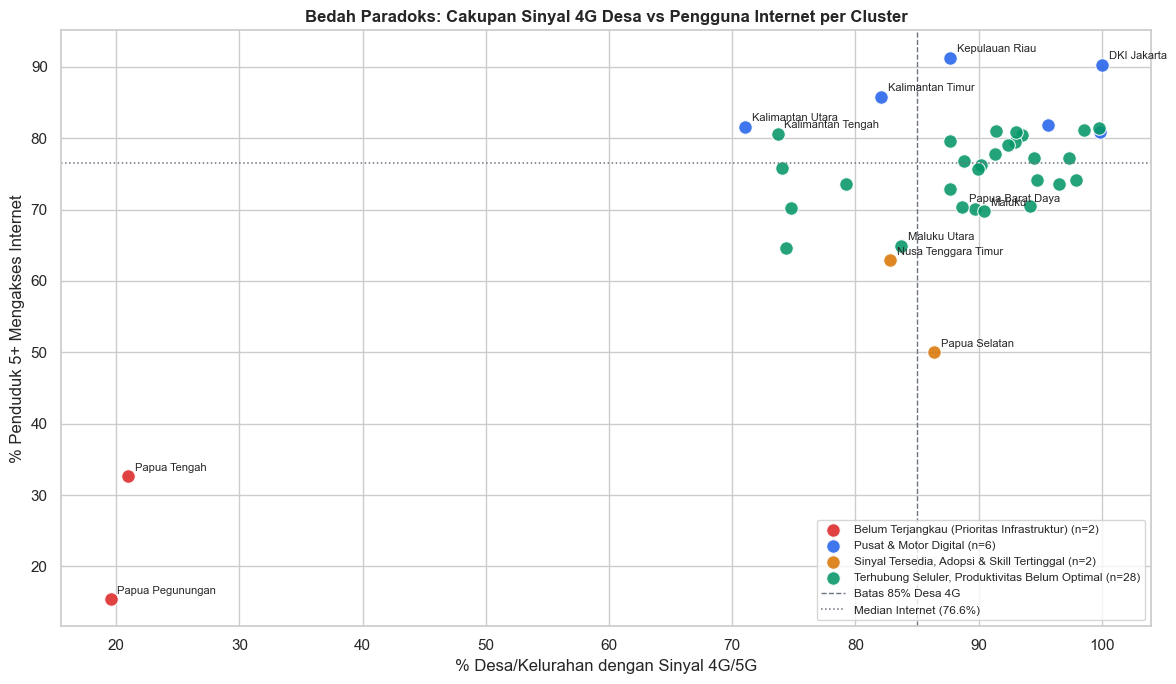

In [5]:
med_hp = df["pct_hp"].median()
med_net = df["pct_internet"].median()
med_skill = df["pct_skill_tik"].median()

p1 = df[(df["pct_hp"] > med_hp) & (df["pct_internet"] < med_net)][
    ["provinsi", "nama_cluster", "pct_hp", "pct_internet"]
]
p2 = df[(df["pct_desa_4g"] >= 80) & (df["pct_skill_tik"] < med_skill)][
    ["provinsi", "nama_cluster", "pct_desa_4g", "pct_skill_tik", "pct_internet"]
].sort_values("pct_skill_tik")
p3 = df[(df["pct_internet"] > med_net) & (df["pct_desa_4g"] < 85)][
    ["provinsi", "nama_cluster", "pct_desa_4g", "pct_internet", "pct_hp"]
].sort_values("pct_desa_4g")

print(f"=== Paradoks 1: HP > median ({med_hp:.1f}%) tapi Internet < median ({med_net:.1f}%) ===")
display(p1 if len(p1) else "Tidak ada")

print(f"\n=== Paradoks 2: Sinyal 4G >= 80% tapi Skill TIK < median ({med_skill:.1f}%) ===")
display(p2)

print(f"\n=== Paradoks 3: Internet > median ({med_net:.1f}%) tapi Sinyal 4G Desa < 85% ===")
display(p3)

# Visualisasi kuadran Sinyal 4G vs Pengguna Internet berwarna per cluster
palette = {
    NAMA[0]: "#2563eb",
    NAMA[1]: "#059669",
    NAMA[2]: "#d97706",
    NAMA[3]: "#dc2626",
}
fig, ax = plt.subplots(figsize=(12, 7))
for cname, grp in df.groupby("nama_cluster"):
    ax.scatter(grp["pct_desa_4g"], grp["pct_internet"], s=95, color=palette[cname],
               label=f"{cname} (n={len(grp)})", alpha=0.88, edgecolor="white", linewidth=0.8)

ax.axvline(85, color="#6b7280", linestyle="--", linewidth=1.0, label="Batas 85% Desa 4G")
ax.axhline(med_net, color="#6b7280", linestyle=":", linewidth=1.1, label=f"Median Internet ({med_net:.1f}%)")

# Beri label provinsi kunci & paradoks
key_provs = set(p2["provinsi"].head(5)) | set(p3["provinsi"]) | {"DKI Jakarta", "Kepulauan Riau", "Papua Tengah", "Papua Pegunungan"}
for _, row in df[df["provinsi"].isin(key_provs)].iterrows():
    ax.annotate(row["provinsi"], (row["pct_desa_4g"], row["pct_internet"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)

ax.set_title("Bedah Paradoks: Cakupan Sinyal 4G Desa vs Pengguna Internet per Cluster", fontsize=12, fontweight="bold")
ax.set_xlabel("% Desa/Kelurahan dengan Sinyal 4G/5G")
ax.set_ylabel("% Penduduk 5+ Mengakses Internet")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
save_matplotlib(fig, "04_analisis_paradoks")
plt.show()

## 5. Validasi Eksternal & Evaluasi Provinsi Perbatasan (K-Means vs Ward)
- Jika variabel konteks (`ip_tik` atau `pdrb_per_kapita`) sudah ditambahkan ke dataset, cell ini otomatis mengecek apakah cluster yang lebih maju juga memiliki IP-TIK/PDRB lebih tinggi.
- Cell ini juga menampilkan provinsi mana saja yang penempatannya berbeda antara **K-Means** dan **Hierarchical Ward** — ini menunjukkan provinsi "zona perbatasan" antar-cluster.

In [ ]:
val_cols = [c for c in VALIDATION_VARS if c in df.columns]
if val_cols:
    print("=== Validasi Eksternal per Cluster ===")
    display(df.groupby("nama_cluster")[val_cols].agg(["mean", "median"]).round(2))
else:
    print("Info: Variabel validasi eksternal (ip_tik / pdrb_per_kapita) belum dimasukkan ke data master.")
    print("      Opsional: unduh tabel IP-TIK atau PDRB per kapita BPS lalu gabungkan di Notebook 01 untuk mengaktifkan bagian ini.")
# Cek provinsi perbatasan antara K-Means dan Hierarchical Ward
diff_ward = df[df["cluster"] != df["cluster_ward"]][
    ["provinsi", "cluster", "cluster_ward", "nama_cluster"] + FEATURES
]
sepakat = len(df) - len(diff_ward)
print(f"\nKesepakatan K-Means vs Ward: {sepakat}/{len(df)} provinsi ({sepakat/len(df)*100:.1f}%)")
print("Provinsi zona perbatasan (berbeda antara K-Means vs Ward):")
display(diff_ward)

Info: Variabel validasi eksternal (ip_tik / pdrb_per_kapita) belum dimasukkan ke data master.
      Opsional: unduh tabel IP-TIK atau PDRB per kapita BPS lalu gabungkan di Notebook 01 untuk mengaktifkan bagian ini.

Kesepakatan K-Means vs Ward: 36/38 provinsi (94.7%)
Provinsi zona perbatasan (berbeda antara K-Means vs Ward):


,provinsi,cluster,cluster_ward,nama_cluster,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls
18,Nusa Tenggara Timur,2,1,"Sinyal Tersedia, Adopsi & Skill Tertinggal",62.91,55.97,15.54,82.82,86.40,8.35
23,Kalimantan Utara,0,1,Pusat & Motor Digital,81.58,79.45,25.95,71.07,96.53,9.53


## 6. Simpan Hasil Final untuk Dashboard Streamlit
Kita perbarui `data/processed/provinsi_cluster.csv` dengan kolom `nama_cluster`, `hambatan_utama`, dan `rekomendasi`, serta simpan ringkasan matriks kebijakan ke `data/processed/ringkasan_cluster_kebijakan.csv`.

In [7]:
df.to_csv(CLUSTER_FILE, index=False)
summary_path = DATA_PROCESSED / "ringkasan_cluster_kebijakan.csv"
matriks_kebijakan.to_csv(summary_path, index=False)

print(f"File final dashboard disimpan ke : {CLUSTER_FILE}")
print(f"Matriks kebijakan disimpan ke    : {summary_path}")
print(f"Kolom akhir provinsi_cluster.csv : {list(df.columns)}")

File final dashboard disimpan ke : C:\Users\USER\Documents\indonesia_digital_divide_clustering\data\processed\provinsi_cluster.csv
Matriks kebijakan disimpan ke    : C:\Users\USER\Documents\indonesia_digital_divide_clustering\data\processed\ringkasan_cluster_kebijakan.csv
Kolom akhir provinsi_cluster.csv : ['provinsi', 'pct_internet', 'pct_hp', 'pct_komputer', 'pct_desa_4g', 'pct_skill_tik', 'rls', 'cluster', 'cluster_ward', 'pc1', 'pc2', 'nama_cluster', 'hambatan_utama', 'rekomendasi']


## 7. Ringkasan Akhir Analisis

### Q&A
- **Provinsi mana yang punya pola kesiapan digital serupa dan apa hambatan utamanya?** 38 provinsi Indonesia terbagi tegas ke dalam 4 tipologi: **Pusat & Motor Digital** (6 provinsi — fokus ekonomi digital & pemerataan pedalaman), **Terhubung Seluler, Produktivitas Belum Optimal** (28 provinsi — perangkat komputer rendah & pemanfaatan produktif), **Sinyal Tersedia, Adopsi & Skill Tertinggal** (2 provinsi: NTT & Papua Selatan — hambatan adopsi dan literasi meski 4G >82%), serta **Belum Terjangkau** (2 provinsi: Papua Tengah & Papua Pegunungan — darurat infrastruktur dasar 4G ~20% dan pendidikan).

### Data Analysis Key Findings
- **Kesesuaian model sangat tinggi:** K-Means dan Hierarchical Ward sepakat pada **36 dari 38 provinsi (94,7%)**; hanya 2 provinsi perbatasan (Kalimantan Utara dan Nusa Tenggara Timur) yang berbeda penempatan.
- **Paradoks terbukti di data nyata:** Papua Selatan (`86,4%` desa 4G) dan NTT (`82,8%` desa 4G) membuktikan ketersediaan sinyal belum otomatis diikuti keterampilan TIK dan akses internet; sebaliknya Kalimantan Utara (`71,1%` desa 4G) dan Kalimantan Tengah (`73,7%` desa 4G) menunjukkan adopsi internet di atas median meski cakupan sinyal desa masih tertinggal.
- **Perbedaan terbesar kelas atas vs menengah ada pada perangkat produktif:** Kepemilikan komputer rumah tangga di Cluster 0 (~31%) jauh melampaui Cluster 1 (~18,5%), meski kepemilikan HP dan sinyal 4G relatif berdekatan.

### Insights or Next Steps
- Kebijakan transformasi digital nasional tidak boleh seragam: intervensi BTS/satelit harus diprioritaskan pada **Cluster 3**, program literasi & akses perangkat bersama pada **Cluster 2**, peningkatan produktivitas UMKM/komputer pada **Cluster 1**, dan penguatan ekonomi digital lanjut pada **Cluster 0**.
- **Langkah berikutnya:** jalankan dashboard interaktif (`streamlit run app/streamlit_app.py`), tambahkan file peta GeoJSON 38 provinsi ke `data/geo/indonesia_provinsi.geojson`, lalu lengkapi bagian temuan & dokumentasi di `README.md`.